In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from datetime import datetime
from pathlib import Path
import torch

import sys
sys.path.append("../../tools")
import prepare as prep
import functions as func
import generation as gr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(func)


In [3]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis labels (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick labels (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})


In [4]:
load_dir1 = Path(f"../../saved_models/sta_entropy_15fold/sp3to20_MD_transpt3_r9")
load_dir2 = Path(f"../../saved_models/diversity_15fold/sp3to20_MD_transpt3_r1")
load_dir3 = Path(f"../../saved_models/num_stable_states_15fold/sp3to20_NS_transpt3_r7")
load_dir4 = Path(f"../../saved_models/fluctuation_3fold_v0/sp3to20_Fl_transpt3_r1")
load_dir5 = Path(f"../../saved_models/swi_species_15fold/sp3to20_SS_transpt3_r13")
emodel = func.load_saved_model_MD(load_dir1, device)
dmodel = func.load_saved_model_MD(load_dir2, device)
nmodel = func.load_saved_model_NS(load_dir3, device)
fmodel = func.load_saved_model_MD(load_dir4, device)
smodel = func.load_saved_model_SS(load_dir5, device)
epredictor = func.Predictor(emodel)
dpredictor = func.Predictor(dmodel)
npredictor = func.Predictor(nmodel)
fpredictor = func.Predictor(fmodel)
spredictor = func.Predictor(smodel)


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [5]:
def plot_discrete_scatter(data1, data2, figsize=(1, 1), random_state=42, save_path=None):
    
    rng = np.random.default_rng(random_state)

    # All possible discrete values
    values = np.sort(np.unique(np.concatenate([data1, data2])))

    fig, ax = plt.subplots(figsize=figsize, dpi=200)

    x1 = 0
    x2 = 1
    jitter_width = 0.12

    # jitter
    jitter1 = x1 + rng.uniform(-jitter_width, jitter_width, len(data1))
    jitter2 = x2 + rng.uniform(-jitter_width, jitter_width, len(data2))

    ax.scatter(
        jitter1, data1,
        s=8, facecolor="#70A782",
        edgecolor="none", alpha=0.5
    )

    ax.scatter(
        jitter2, data2,
        s=8, facecolor="#F6D05E",
        edgecolor="none", alpha=0.5
    )

    # Use discrete values on y-axis
    ax.set_yticks(values)
    ax.set_yticklabels([str(v) for v in values])

    ax.set_xticks([x1, x2])
    ax.set_xticklabels(["X1", "X2"])

    ax.set_ylabel("Survival fraction")
    ax.set_xlim(-0.5, 1.5)

    ax.tick_params(direction="in")

    for spine in ax.spines.values():
        spine.set_color("black")

    ax.grid(False)

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=1000,
            bbox_inches="tight",
            transparent=True
        )

    plt.show()

    return fig, ax

def plot_discrete_violin(data1, data2, figsize=(1, 1), save_path=None):

    data = [data1, data2]
    positions = [0, 1]
    colors = ["#70A782", "#F6D05E"]
    fig, ax = plt.subplots(figsize=figsize, dpi=200)

    vp = plt.violinplot(
        data,
        positions=positions,
        widths=0.5,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    # violin color
    for body, color in zip(vp['bodies'], colors):
        body.set_facecolor(color)
        body.set_edgecolor('none')
        body.set_alpha(0.75)

    # mean line
    means = [np.mean(d) for d in data]

    for x, m in zip(positions, means):
        plt.hlines(
            m,
            x - 0.15,
            x + 0.15,
            color='black',
            linewidth=1,
            linestyle='--',
            zorder=5
        )

    # x-axis
    plt.xticks(
        positions,
        ['Fluc', 'Unfluc']
    )

    plt.ylabel("Survival fraction")

    # axes
    ax.tick_params(direction="in")

    for spine in ax.spines.values():
        spine.set_color("black")

    plt.grid(False)
    plt.xlim(-0.5, 1.5)
    # survival fraction
    plt.ylim(-0.1, 1.1)

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=1000,
            bbox_inches='tight',
            transparent=True
        )

    plt.show()

    return fig, ax


**Predicting fluctuation**

In [58]:
#df = pd.read_csv("gamma5_fluc.csv")
#df = pd.read_csv("gamma5.csv")
#df = pd.read_csv("gamma5_allneg.csv")
df = pd.read_csv("../Fig4/random2.csv")
df = df.dropna()
df["relative_H"] = df["relative_H"].clip(lower=0, upper=1)
df["relative_D"] = df["relative_D"].clip(lower=0, upper=1)

MaxNum = 20

# Xnum_pad = df.iloc[:, :MaxNum**2+MaxNum].values
# df["fluctuation"] = fpredictor.predict_array_Fl(Xnum_pad, device, 0.6)


**Survival fraction validation**

In [ ]:
n_real = 8
sub_df = df[(df["richness"]==n_real)]
#sub_df = sub_df[(sub_df["gamma_mean"]>0.9)&(sub_df["gamma_mean"]<1.1)]

Xnum_pad_s = sub_df[sub_df["fluctuation"]==0].iloc[:20, :MaxNum**2+MaxNum].values
Xnum_pad_f = sub_df[sub_df["fluctuation"]==1].iloc[:20, :MaxNum**2+MaxNum].values
Xnum_s = prep.recovery_Xnum(Xnum_pad_s, n_real, MaxNum)
Xnum_f = prep.recovery_Xnum(Xnum_pad_f, n_real, MaxNum)
Xynum_s = gr.predict_numerical(Xnum_s, n_real, repeat=200, timespan=np.arange(0,800.1,.1))
Xynum_f = gr.predict_numerical(Xnum_f, n_real, repeat=200, timespan=np.arange(0,800.1,.1))

results = np.concatenate((Xynum_s,Xynum_f), axis=0)
pd.DataFrame(results).to_csv(f"C_surfrac_sp8_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv", index=False)
#plot_discrete_scatter(Xynum_f[:,-1].reshape(-1,1), Xynum_s[:,-1].reshape(-1,1), figsize=(1, 1), random_state=42, save_path=None)
plot_discrete_violin(Xynum_f[:,-1], Xynum_s[:,-1], figsize=(1, 1), 
                     save_path=f"C_surfrac_sp8_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf")


In [ ]:
n_real = 20
sub_df = df[(df["richness"]==n_real)]
#sub_df = sub_df[(sub_df["gamma_mean"]>0.9)&(sub_df["gamma_mean"]<1.1)]

Xnum_pad_s = sub_df[sub_df["fluctuation"]==0].iloc[:20, :MaxNum**2+MaxNum].values
Xnum_pad_f = sub_df[sub_df["fluctuation"]==1].iloc[:20, :MaxNum**2+MaxNum].values
Xnum_s = prep.recovery_Xnum(Xnum_pad_s, n_real, MaxNum)
Xnum_f = prep.recovery_Xnum(Xnum_pad_f, n_real, MaxNum)
Xynum_s = gr.predict_numerical(Xnum_s, n_real, repeat=200, timespan=np.arange(0,800.1,.1))
Xynum_f = gr.predict_numerical(Xnum_f, n_real, repeat=200, timespan=np.arange(0,800.1,.1))

results = np.concatenate((Xynum_s,Xynum_f), axis=0)
pd.DataFrame(results).to_csv(f"C_surfrac_sp20_gamma_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv", index=False)
#plot_discrete_scatter(Xynum_f[:,-1].reshape(-1,1), Xynum_s[:,-1].reshape(-1,1), figsize=(1, 1), random_state=42, save_path=None)
plot_discrete_violin(Xynum_f[:,-1], Xynum_s[:,-1], figsize=(1, 1), 
                     save_path=f"C_surfrac_sp20_gamma_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf")


**Numerical fluctuation**

In [60]:
#df = pd.read_csv("random2_fluc.csv")
df = pd.read_csv("../Fig4/random2_upto20.csv")
df = df.dropna()
df["relative_H"] = df["relative_H"].clip(lower=0, upper=1)
df["relative_D"] = df["relative_D"].clip(lower=0, upper=1)


**emer_property~richness**

In [53]:
def plot_fluctuation_boxplot(df, property_col="relative_H", richness_list=range(4, 21), 
                             random_state=42, figsize=(6, 1), save_path=None, ylim=None):

    rng = np.random.default_rng(random_state)

    required_cols = ["richness", "fluctuation", property_col]
    for col in required_cols:
        if col not in df.columns:
            raise ValueError(f"Column not found in DataFrame: {col}")

    oscillating_color = "#70A782"
    nonoscillating_color = "#F6D05E"

    fig, ax = plt.subplots(figsize=figsize, dpi=200)

    richness_list = list(richness_list)
    x_centers = np.arange(len(richness_list))
    offset = 0.2
    x_osc = x_centers - offset
    x_non = x_centers + offset

    for i, richness in enumerate(richness_list):
        df_r = df[df["richness"] == richness]

        data_osc = df_r.loc[df_r["fluctuation"] == 1, property_col].dropna().to_numpy()
        data_non = df_r.loc[df_r["fluctuation"] == 0, property_col].dropna().to_numpy()

        n_osc_original = len(data_osc)
        n_non_original = len(data_non)
        n_used = min(n_osc_original, n_non_original)

        if n_used == 0:
            print(f"Warning: richness={richness} lacks two-class samples, skipped.")
            continue

        if n_osc_original > n_used:
            data_osc = data_osc[rng.choice(n_osc_original, size=n_used, replace=False)]

        if n_non_original > n_used:
            data_non = data_non[rng.choice(n_non_original, size=n_used, replace=False)]

        print(f"richness = {richness:2d} | original: Osc={n_osc_original}, Non-Osc={n_non_original} | used={n_used}")

        # ax.boxplot(data_osc, positions=[x_osc[i]], widths=0.22, patch_artist=True, showfliers=False,
        #            boxprops=dict(facecolor=oscillating_color, edgecolor='black', linewidth=0.5),
        #            medianprops=dict(color='black', linewidth=0.5),
        #            whiskerprops=dict(color='black', linewidth=0.5),
        #            capprops=dict(color='black', linewidth=0.5))

        # ax.boxplot(data_non, positions=[x_non[i]], widths=0.22, patch_artist=True, showfliers=False,
        #            boxprops=dict(facecolor=nonoscillating_color, edgecolor='black', linewidth=0.5),
        #            medianprops=dict(color='black', linewidth=0.5),
        #            whiskerprops=dict(color='black', linewidth=0.5),
        #            capprops=dict(color='black', linewidth=0.5))

        mean_osc = np.mean(data_osc)
        mean_non = np.mean(data_non)

        ax.hlines(mean_osc, x_osc[i] - 0.1, x_osc[i] + 0.1, color='black', linewidth=0.5, linestyle='--', zorder=5)
        ax.hlines(mean_non, x_non[i] - 0.1, x_non[i] + 0.1, color='black', linewidth=0.5, linestyle='--', zorder=5)

        max_points = 100

        scatter_osc = data_osc if len(data_osc) <= max_points else data_osc[rng.choice(len(data_osc), size=max_points, replace=False)]
        scatter_non = data_non if len(data_non) <= max_points else data_non[rng.choice(len(data_non), size=max_points, replace=False)]

        jitter_width = 0.075
        jitter_osc = x_osc[i] + rng.uniform(-jitter_width, jitter_width, len(scatter_osc))
        jitter_non = x_non[i] + rng.uniform(-jitter_width, jitter_width, len(scatter_non))

        ax.scatter(jitter_osc, scatter_osc, s=5, facecolor=oscillating_color, edgecolor='none', alpha=0.5, zorder=2, rasterized=True,)
        ax.scatter(jitter_non, scatter_non, s=5, facecolor=nonoscillating_color, edgecolor='none', alpha=0.5, zorder=2, rasterized=True,)

    ax.set_xticks(x_centers)
    ax.set_xticklabels([str(x) for x in richness_list])
    ax.set_xlabel("Richness")

    if property_col == "relative_H":
        ax.set_ylabel(r"$\mathcal{H}$")
    elif property_col == "relative_D":
        ax.set_ylabel(r"$\mathcal{D}$")
    else:
        ax.set_ylabel(property_col)

    for spine in ax.spines.values():
        #spine.set_linewidth(0.8)
        spine.set_color('black')

    ax.grid(False)
    ax.set_xlim(-0.5, len(richness_list) - 0.5)
    if ylim != None:
        ax.set_ylim(ylim)
    ax.tick_params(direction='in')

    legend_elements = [
        Patch(facecolor=oscillating_color, edgecolor='black', linewidth=0.5, label='Fluctuation'),
        Patch(facecolor=nonoscillating_color, edgecolor='black', linewidth=0.5, label='Non-Fluctuation')
    ]

    ax.legend(handles=legend_elements, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.03),
              ncol=2, handlelength=1.2, handletextpad=0.4, columnspacing=1.0)

    if save_path is not None:
        plt.savefig(save_path, dpi=1000, bbox_inches='tight', transparent=True)

    plt.show()
    
    return fig, ax

def plot_pls1_fluctuation(df, X, y_col="relative_H", n_bins=5, fluctuation_col="fluctuation",
    random_state=42, max_points=100, jitter_width=0.075, figsize=(3, 1), save_path=None, ylim=None):

    """
    Sort by PLS1, then equal-frequency binning, and plot
    scatter points and mean lines for fluctuation / non-fluctuation samples across PLS1 bins.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing y_col and fluctuation_col.
        Each row corresponds to one sample.

    X : array-like
        Original parameter matrix for PLS.
        Number of rows must match df.

    y_col : str
        Column for the y-axis, e.g. "relative_D" or "relative_H".

    n_bins : int
        Number of PLS1 bins, e.g. 5.

    fluctuation_col : str
        Fluctuation flag column: 0 = non-fluctuation, 1 = fluctuation.

    random_state : int
        Random seed.

    max_points : int
        Max scatter points per bin per fluctuation type.
        None means plot all.

    jitter_width : float
        Horizontal jitter width.

    figsize : tuple
        Figure size.

    save_path : str or None
        Save path. None means do not save.

    Returns
    -------
    fig, ax, df_result
        fig, ax : matplotlib figure objects
        df_result : DataFrame with added PLS1 and PLS1_bin columns
    """

    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    from sklearn.preprocessing import StandardScaler
    from sklearn.cross_decomposition import PLSRegression

    # 1. Check data
    required_cols = [y_col, fluctuation_col]

    for col in required_cols:
        if col not in df.columns:
            raise ValueError(f"Column not found in DataFrame: {col}")

    X = np.asarray(X)

    if len(df) != X.shape[0]:
        raise ValueError(f"Sample count mismatch: df={len(df)}, X={X.shape[0]}")

    if n_bins < 2:
        raise ValueError("n_bins must be at least 2.")

    # 2. StandardScaler + PLS
    X_scaled = StandardScaler().fit_transform(X)

    pls = PLSRegression(n_components=2)
    pls.fit(X_scaled, df[y_col])

    # PLS1
    pls1 = pls.x_scores_[:, 0]

    # 3. Sort by PLS1, then equal-frequency binning
    df_result = df.copy()
    df_result["PLS1"] = pls1

    # Sort PLS1 from low to high
    sort_index = np.argsort(pls1)

    # Initialize bin
    bin_labels = np.empty(len(df), dtype=int)

    # Allocate evenly into n_bins bins by rank
    #
    # E.g. 1000 samples, 5 bins:
    # bin 0: lowest ~200
    # bin 1: next ~200
    # ...
    #
    # So not equal-width over PLS1 value range.
    ranks = np.empty(len(df), dtype=int)
    ranks[sort_index] = np.arange(len(df))

    bin_labels = (ranks * n_bins // len(df)).astype(int)

    # Clip to prevent out-of-bounds in edge cases
    bin_labels = np.clip(bin_labels, 0, n_bins - 1)

    df_result["PLS1_bin"] = bin_labels

    # 4. Print PLS1 range and sample count for each bin
    print("\nPLS1 bins:")

    for i in range(n_bins):

        df_bin = df_result[df_result["PLS1_bin"] == i]

        pls_min = df_bin["PLS1"].min()
        pls_max = df_bin["PLS1"].max()

        n_total = len(df_bin)
        n_osc = (df_bin[fluctuation_col] == 1).sum()
        n_non = (df_bin[fluctuation_col] == 0).sum()

        print(
            f"Bin {i + 1}: "
            f"PLS1 = [{pls_min:.3f}, {pls_max:.3f}], "
            f"N = {n_total}, "
            f"Osc = {n_osc}, "
            f"Non-Osc = {n_non}"
        )

    # 5. Plot parameters
    rng = np.random.default_rng(random_state)

    oscillating_color = "#70A782"
    nonoscillating_color = "#F6D05E"

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    x_centers = np.arange(n_bins)

    # Place two states on opposite sides of bin center
    offset = 0.18

    x_osc = x_centers - offset
    x_non = x_centers + offset

    # Store mean of each bin
    mean_osc_list = []
    mean_non_list = []

    # 6. Draw scatter for each PLS1 bin
    for i in range(n_bins):

        df_bin = df_result[df_result["PLS1_bin"] == i]

        # fluctuation
        data_osc = (df_bin.loc[df_bin[fluctuation_col] == 1, y_col].dropna().to_numpy())
        # non-fluctuation
        data_non = (df_bin.loc[df_bin[fluctuation_col] == 0, y_col].dropna().to_numpy())

        # Random subsample for plotting
        if max_points is not None:

            if len(data_osc) > max_points:
                data_osc_plot = data_osc[
                    rng.choice(
                        len(data_osc),
                        size=max_points,
                        replace=False
                    )
                ]
            else:
                data_osc_plot = data_osc

            if len(data_non) > max_points:
                data_non_plot = data_non[
                    rng.choice(
                        len(data_non),
                        size=max_points,
                        replace=False
                    )
                ]
            else:
                data_non_plot = data_non

        else:
            data_osc_plot = data_osc
            data_non_plot = data_non

        # jitter
        jitter_osc = (
            x_osc[i]
            + rng.uniform(
                -jitter_width,
                jitter_width,
                len(data_osc_plot)
            )
        )

        jitter_non = (
            x_non[i]
            + rng.uniform(
                -jitter_width,
                jitter_width,
                len(data_non_plot)
            )
        )

        # scatter
        ax.scatter(
            jitter_osc,
            data_osc_plot,
            s=5,
            facecolor=oscillating_color,
            edgecolor="none",
            alpha=0.50,
            zorder=2,
            rasterized=True,
        )

        ax.scatter(
            jitter_non,
            data_non_plot,
            s=5,
            facecolor=nonoscillating_color,
            edgecolor="none",
            alpha=0.50,
            zorder=2,
            rasterized=True,
        )

        # Mean
        mean_osc = (
            np.mean(data_osc)
            if len(data_osc) > 0
            else np.nan
        )

        mean_non = (
            np.mean(data_non)
            if len(data_non) > 0
            else np.nan
        )

        mean_osc_list.append(mean_osc)
        mean_non_list.append(mean_non)

        # Mean horizontal line
        if not np.isnan(mean_osc):

            ax.hlines(
                mean_osc,
                x_osc[i] - 0.08,
                x_osc[i] + 0.08,
                color="black",
                linewidth=0.7,
                linestyle="--",
                zorder=5
            )

        if not np.isnan(mean_non):

            ax.hlines(
                mean_non,
                x_non[i] - 0.08,
                x_non[i] + 0.08,
                color="black",
                linewidth=0.7,
                linestyle="--",
                zorder=5
            )

    # 7. Connect means across bins
    mean_osc_array = np.asarray(mean_osc_list)
    mean_non_array = np.asarray(mean_non_list)

    # Only connect points with data
    valid_osc = ~np.isnan(mean_osc_array)
    valid_non = ~np.isnan(mean_non_array)

    ax.plot(
        x_osc[valid_osc],
        mean_osc_array[valid_osc],
        color="#535353",
        linewidth=1.8,
        alpha=0.65,
        zorder=4
    )

    ax.plot(
        x_non[valid_non],
        mean_non_array[valid_non],
        color="#ABABAB",
        linewidth=1.8,
        alpha=0.65,
        zorder=4
    )
    
    # 8. X/Y axes
    ax.set_xticks(x_centers)

    # Use PLS1 range as category label
    bin_labels_text = []

    for i in range(n_bins):

        df_bin = df_result[df_result["PLS1_bin"] == i]

        pls_min = df_bin["PLS1"].min()
        pls_max = df_bin["PLS1"].max()

        bin_labels_text.append(f"{pls_min:.2f} – {pls_max:.2f}")

    ax.set_xticklabels(bin_labels_text)

    # y-axis
    if y_col == "relative_H":
        ax.set_xlabel(r"PLS1 of $\mathcal{H}$")
        ax.set_ylabel(r"$\mathcal{H}$")
        
    elif y_col == "relative_D":
        ax.set_xlabel(r"PLS1 of $\mathcal{D}$")
        ax.set_ylabel(r"$\mathcal{D}$")

    # 9. Plot styling
    for spine in ax.spines.values():
        spine.set_color("black")

    ax.grid(False)
    ax.set_xlim(-0.5, n_bins - 0.5)
    if ylim != None:
        ax.set_ylim(ylim)
    ax.tick_params(direction="in")

    # 10. Legend
    legend_elements = [

        Patch(
            facecolor=oscillating_color,
            edgecolor="black",
            linewidth=0.5,
            label="Fluctuation"
        ),

        Patch(
            facecolor=nonoscillating_color,
            edgecolor="black",
            linewidth=0.5,
            label="Non-Fluctuation"
        )
    ]

    ax.legend(
        handles=legend_elements,
        frameon=False,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.4),
        ncol=2,
        handlelength=1.2,
        handletextpad=0.4,
        columnspacing=1.0
    )

    # 11. Save
    if save_path is not None:
        plt.savefig(save_path, dpi=1000, bbox_inches="tight", transparent=True)
    plt.show()

    return fig, ax, df_result

def fit_pls1_axis(df, X, y_col="relative_H", n_bins=5, save_path="pls1_axis.joblib",):
    """
    Fit PLS1 axis on old data, save scaler, PLS model and bin edges.
    """
    import numpy as np
    import joblib
    from sklearn.preprocessing import StandardScaler
    from sklearn.cross_decomposition import PLSRegression

    X = np.asarray(X, dtype=float)
    y = df[y_col].to_numpy(dtype=float)

    if len(df) != X.shape[0]:
        raise ValueError("Sample count mismatch between df and X.")

    if not np.isfinite(X).all() or not np.isfinite(y).all():
        raise ValueError("X and y must not contain NaN or infinite values.")

    # 1. Standardize: fit only on old data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # 2. Fit PLS
    pls = PLSRegression(n_components=2)
    pls.fit(X_scaled, y)

    # 3. Compute PLS1 coordinates for old data
    pls1 = pls.transform(X_scaled)[:, 0]

    # 4. Sort old data, build equal-frequency bin edges
    sorted_pls1 = np.sort(pls1)
    n = len(sorted_pls1)

    # Record start/end position of each bin after sorting
    # Consistent with rank * n_bins // n binning rule
    split_indices = [
        (i * n) // n_bins for i in range(n_bins + 1)
    ]

    # Actual min and max PLS1 of each bin
    bin_ranges = []

    for i in range(n_bins):
        start = split_indices[i]
        end = split_indices[i + 1]

        bin_ranges.append((
            float(sorted_pls1[start]),
            float(sorted_pls1[end - 1])
        ))

    # Use midpoint between adjacent bins as fixed boundary for new data
    # Preserves old binning while handling new data between boundaries
    bin_edges = np.array(
        [r[1] / 2 + bin_ranges[i + 1][0] / 2
         for i, r in enumerate(bin_ranges[:-1])],
        dtype=float
    )

    model_bundle = {
        "scaler": scaler,
        "pls": pls,
        "y_col": y_col,
        "n_bins": n_bins,
        "bin_ranges": bin_ranges,
        "bin_edges": bin_edges,
        "n_features": X.shape[1],
    }

    if save_path is not None:
        joblib.dump(model_bundle, save_path)
        print(f"PLS1 axis saved to: {save_path}")

    print("\nReference PLS1 bins:")
    for i, (lo, hi) in enumerate(bin_ranges):
        print(
            f"Bin {i + 1}: PLS1 = [{lo:.3f}, {hi:.3f}]"
        )

    return model_bundle

def plot_pls1_fluctuation_new(df, X, model_bundle, fluctuation_col="fluctuation",
    random_state=42, max_points=100, jitter_width=0.075, figsize=(3, 1), save_path=None, ylim=None,
):
    """
    Project new data onto pre-fitted PLS1 axis, bin, and plot.
    """
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch

    scaler = model_bundle["scaler"]
    pls = model_bundle["pls"]
    y_col = model_bundle["y_col"]
    n_bins = model_bundle["n_bins"]
    bin_ranges = model_bundle["bin_ranges"]
    bin_edges = model_bundle["bin_edges"]

    X = np.asarray(X, dtype=float)

    if len(df) != X.shape[0]:
        raise ValueError("Sample count mismatch between df and X.")

    if X.shape[1] != model_bundle["n_features"]:
        raise ValueError("Feature count mismatch between old and new X.")

    for col in [y_col, fluctuation_col]:
        if col not in df.columns:
            raise ValueError(f"Column not found in DataFrame: {col}")

    if not np.isfinite(X).all():
        raise ValueError("X must not contain NaN or infinite values.")

    # 1. Use old scaler and PLS to project onto original PLS1 axis
    X_scaled = scaler.transform(X)
    pls1 = pls.transform(X_scaled)[:, 0]

    df_result = df.copy()
    df_result["PLS1"] = pls1

    # 2. Bin using fixed old boundaries, no re-binning for new data
    df_result["PLS1_bin"] = np.digitize(
        pls1, bin_edges
    ).astype(int)

    print("\nNew data in reference PLS1 bins:")
    for i in range(n_bins):
        df_bin = df_result[df_result["PLS1_bin"] == i]

        n_total = len(df_bin)
        n_osc = (df_bin[fluctuation_col] == 1).sum()
        n_non = (df_bin[fluctuation_col] == 0).sum()

        lo, hi = bin_ranges[i]

        print(
            f"Bin {i + 1}: reference PLS1 = [{lo:.3f}, {hi:.3f}], "
            f"N = {n_total}, Osc = {n_osc}, Non-Osc = {n_non}"
        )

    # 3. Plot
    rng = np.random.default_rng(random_state)

    oscillating_color = "#70A782"
    nonoscillating_color = "#F6D05E"

    fig, ax = plt.subplots(figsize=figsize, dpi=200)

    x_centers = np.arange(n_bins)
    offset = 0.18
    x_osc = x_centers - offset
    x_non = x_centers + offset

    mean_osc_list = []
    mean_non_list = []

    for i in range(n_bins):
        df_bin = df_result[df_result["PLS1_bin"] == i]

        data_osc = (
            df_bin.loc[df_bin[fluctuation_col] == 1, y_col]
            .dropna().to_numpy()
        )
        data_non = (
            df_bin.loc[df_bin[fluctuation_col] == 0, y_col]
            .dropna().to_numpy()
        )

        def sample_points(data):
            if max_points is not None and len(data) > max_points:
                return data[
                    rng.choice(len(data), size=max_points, replace=False)
                ]
            return data

        plot_osc = sample_points(data_osc)
        plot_non = sample_points(data_non)

        jitter_osc = x_osc[i] + rng.uniform(
            -jitter_width, jitter_width, len(plot_osc)
        )
        jitter_non = x_non[i] + rng.uniform(
            -jitter_width, jitter_width, len(plot_non)
        )

        ax.scatter(
            jitter_osc, plot_osc,
            s=5, facecolor=oscillating_color,
            edgecolor="none", alpha=0.50,
            zorder=2, rasterized=True,
        )

        ax.scatter(
            jitter_non, plot_non,
            s=5, facecolor=nonoscillating_color,
            edgecolor="none", alpha=0.50,
            zorder=2, rasterized=True,
        )

        mean_osc = np.mean(data_osc) if len(data_osc) else np.nan
        mean_non = np.mean(data_non) if len(data_non) else np.nan

        mean_osc_list.append(mean_osc)
        mean_non_list.append(mean_non)

        if np.isfinite(mean_osc):
            ax.hlines(
                mean_osc, x_osc[i] - 0.08, x_osc[i] + 0.08,
                color="black", linewidth=0.7,
                linestyle="--", zorder=5,
            )

        if np.isfinite(mean_non):
            ax.hlines(
                mean_non, x_non[i] - 0.08, x_non[i] + 0.08,
                color="black", linewidth=0.7,
                linestyle="--", zorder=5,
            )

    # 4. Mean connecting lines
    mean_osc_array = np.asarray(mean_osc_list)
    mean_non_array = np.asarray(mean_non_list)

    valid_osc = np.isfinite(mean_osc_array)
    valid_non = np.isfinite(mean_non_array)

    ax.plot(
        x_osc[valid_osc], mean_osc_array[valid_osc],
        color="#535353", linewidth=1.8, alpha=0.65, zorder=4,
    )

    ax.plot(
        x_non[valid_non], mean_non_array[valid_non],
        color="#ABABAB", linewidth=1.8, alpha=0.65, zorder=4,
    )

    # 5. Show old-data PLS1 ranges on x-axis
    ax.set_xticks(x_centers)
    ax.set_xticklabels([
        f"{lo:.2f} – {hi:.2f}" for lo, hi in bin_ranges
    ])

    if y_col == "relative_H":
        ax.set_xlabel(r"PLS1 of $\mathcal{H}$")
        ax.set_ylabel(r"$\mathcal{H}$")
    elif y_col == "relative_D":
        ax.set_xlabel(r"PLS1 of $\mathcal{D}$")
        ax.set_ylabel(r"$\mathcal{D}$")
    else:
        ax.set_xlabel("PLS1")
        ax.set_ylabel(y_col)

    for spine in ax.spines.values():
        spine.set_color("black")

    ax.grid(False)
    ax.set_xlim(-0.5, n_bins - 0.5)

    if ylim is not None:
        ax.set_ylim(ylim)

    ax.tick_params(direction="in")

    legend_elements = [
        Patch(
            facecolor=oscillating_color, edgecolor="black",
            linewidth=0.5, label="Fluctuation",
        ),
        Patch(
            facecolor=nonoscillating_color, edgecolor="black",
            linewidth=0.5, label="Non-Fluctuation",
        ),
    ]

    ax.legend(
        handles=legend_elements,
        frameon=False,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.4),
        ncol=2,
        handlelength=1.2,
        handletextpad=0.4,
        columnspacing=1.0,
    )

    if save_path is not None:
        plt.savefig(
            save_path, dpi=1000,
            bbox_inches="tight", transparent=True,
        )

    plt.show()

    return fig, ax, df_result


richness =  4 | original: Osc=72, Non-Osc=7928 | used=72
richness =  8 | original: Osc=496, Non-Osc=7504 | used=496
richness = 12 | original: Osc=768, Non-Osc=7232 | used=768
richness = 16 | original: Osc=1353, Non-Osc=6647 | used=1353
richness = 20 | original: Osc=4151, Non-Osc=3849 | used=3849


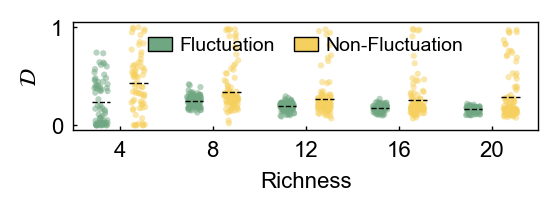

(<Figure size 600x140 with 1 Axes>,
 <Axes: xlabel='Richness', ylabel='$\\mathcal{D}$'>)

In [47]:
#sub_df = df[df["pos_inall"]>0.3]
sub_df = df
plot_fluctuation_boxplot(
    sub_df,
    property_col="relative_D",
    #richness_list=(4, 12, 20),
    #richness_list=range(4, 21),
    richness_list=(4, 8, 12, 16, 20),
    random_state=42,
    figsize=(3, 0.7),
    #ylim=(0, 0.4),
    #save_path=f"C_random2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.svg",
)


**emer_property~PLS1**


PLS1 bins:
Bin 1: PLS1 = [-4.601, -0.496], N = 47999, Osc = 8980, Non-Osc = 39019
Bin 2: PLS1 = [-0.496, 0.438], N = 47998, Osc = 7422, Non-Osc = 40576
Bin 3: PLS1 = [0.438, 3.573], N = 47998, Osc = 3781, Non-Osc = 44217


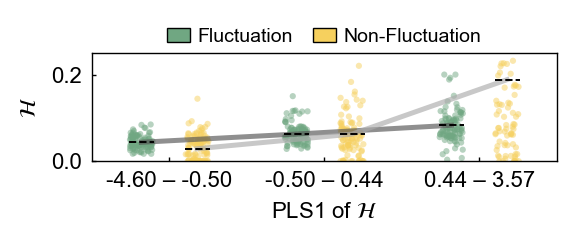

In [34]:
PLSX = df[["richness", "density", "pos_inall", "gamma_neg_mean", "gamma_pos_mean"]].values
fig, ax, df_result = plot_pls1_fluctuation(
    df=df, X=PLSX, y_col="relative_H", n_bins=3, figsize=(3, 0.7), ylim=(0, 0.25),
    #save_path=f"C_PLSbin_random2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.svg",
)


In [59]:
PLSX = df[["richness", "density", "pos_inall", "gamma_neg_mean", "gamma_pos_mean"]].values
model_bundle = fit_pls1_axis(df, PLSX, y_col="relative_D", n_bins=3, save_path="pls1_D_axis.joblib",)


PLS1 轴已保存至: pls1_D_axis.joblib

Reference PLS1 bins:
Bin 1: PLS1 = [-2.899, -0.488]
Bin 2: PLS1 = [-0.488, 0.489]
Bin 3: PLS1 = [0.489, 2.760]



New data in reference PLS1 bins:
Bin 1: reference PLS1 = [-2.899, -0.488], N = 48044, Osc = 2279, Non-Osc = 45765
Bin 2: reference PLS1 = [-0.488, 0.489], N = 47955, Osc = 8752, Non-Osc = 39203
Bin 3: reference PLS1 = [0.489, 2.760], N = 47999, Osc = 12473, Non-Osc = 35526


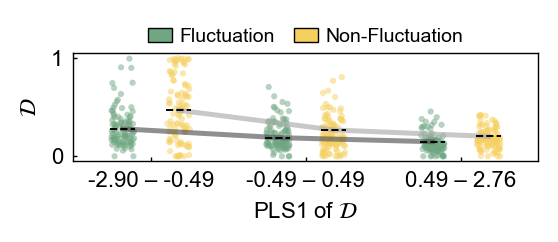

In [62]:
PLSX = df[["richness", "density", "pos_inall", "gamma_neg_mean", "gamma_pos_mean"]].values
fig, ax, df_new_result = plot_pls1_fluctuation_new(df, PLSX, model_bundle, figsize=(3, 0.7), #ylim=(0, 0.25),
                                                   save_path=f"C_PLSbin_random2_upto20_{datetime.now().strftime('%Y%m%d_%H%M%S')}.svg",
                                                   )


**Survival fraction validation**

In [ ]:
df_bin2 = df_result[df_result["PLS1_bin"] == 2].copy()
MaxNum = 20
all_Xynum_s = []
all_Xynum_f = []
samplesize = 30
s_bin2 = df_bin2[df_bin2["fluctuation"]==0].sample(n=samplesize, random_state=42)
f_bin2 = df_bin2[df_bin2["fluctuation"]==1].sample(n=samplesize, random_state=42)

for n_real, sub_df in s_bin2.groupby("richness"):
    n_real = int(n_real)
    Xnum_pad_s = sub_df[sub_df["fluctuation"]==0].iloc[:, :MaxNum**2+MaxNum].values
    Xnum_s = prep.recovery_Xnum(Xnum_pad_s, n_real, MaxNum)
    Xynum_s = gr.predict_numerical(Xnum_s, n_real, repeat=200, timespan=np.arange(0,800.1,.1))
    Xynum_pad_s = func.pad_Xnum_and_ynum_nolegendversion(Xynum_s, n_real, MaxNum)
    all_Xynum_s.append(Xynum_pad_s)

for n_real, sub_df in f_bin2.groupby("richness"):
    n_real = int(n_real)
    Xnum_pad_f = sub_df[sub_df["fluctuation"]==1].iloc[:, :MaxNum**2+MaxNum].values
    Xnum_f = prep.recovery_Xnum(Xnum_pad_f, n_real, MaxNum)
    Xynum_f = gr.predict_numerical(Xnum_f, n_real, repeat=200, timespan=np.arange(0,800.1,.1))
    Xynum_pad_f = func.pad_Xnum_and_ynum_nolegendversion(Xynum_f, n_real, MaxNum)
    all_Xynum_f.append(Xynum_pad_f)

all_Xynum_s = np.concatenate(all_Xynum_s, axis=0)
all_Xynum_f = np.concatenate(all_Xynum_f, axis=0)
results = np.concatenate((all_Xynum_s, all_Xynum_f), axis=0)
pd.DataFrame(results).to_csv(f"C_surfrac_PLS1bin2_random2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv", index=False)
#plot_discrete_scatter(Xynum_f[:,-1].reshape(-1,1), Xynum_s[:,-1].reshape(-1,1), figsize=(1, 1), random_state=42, save_path=None)
# plot_discrete_violin(all_Xynum_f[:,-1], all_Xynum_s[:,-1], figsize=(1, 1), 
#                      save_path=f"C_surfrac_PLS1bin2_random2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf")



PLS1 bins:
Bin 1: PLS1 = [-2.899, -0.488], N = 47999, Osc = 311, Non-Osc = 47688
Bin 2: PLS1 = [-0.488, 0.489], N = 47998, Osc = 6104, Non-Osc = 41894
Bin 3: PLS1 = [0.489, 2.760], N = 47998, Osc = 13768, Non-Osc = 34230


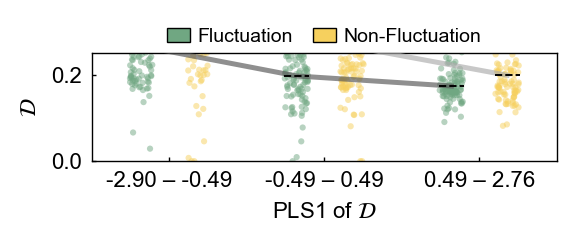

Dealing with richness 3
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
27

In [39]:
PLSX = df[["richness", "density", "pos_inall", "gamma_neg_mean", "gamma_pos_mean"]].values
fig, ax, df_result = plot_pls1_fluctuation(
    df=df, X=PLSX, y_col="relative_D", n_bins=3, figsize=(3, 0.7), ylim=(0, 0.25),
    #save_path=f"C_PLSbin_random2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.svg",
)
df_bin2 = df_result[df_result["PLS1_bin"] == 0].copy()
MaxNum = 20
all_Xynum_s = []
all_Xynum_f = []
samplesize = 30
s_bin2 = df_bin2[df_bin2["fluctuation"]==0].sample(n=samplesize, random_state=42)
f_bin2 = df_bin2[df_bin2["fluctuation"]==1].sample(n=samplesize, random_state=42)

for n_real, sub_df in s_bin2.groupby("richness"):
    n_real = int(n_real)
    Xnum_pad_s = sub_df[sub_df["fluctuation"]==0].iloc[:, :MaxNum**2+MaxNum].values
    Xnum_s = prep.recovery_Xnum(Xnum_pad_s, n_real, MaxNum)
    Xynum_s = gr.predict_numerical(Xnum_s, n_real, repeat=200, timespan=np.arange(0,800.1,.1))
    Xynum_pad_s = func.pad_Xnum_and_ynum_nolegendversion(Xynum_s, n_real, MaxNum)
    all_Xynum_s.append(Xynum_pad_s)

for n_real, sub_df in f_bin2.groupby("richness"):
    n_real = int(n_real)
    Xnum_pad_f = sub_df[sub_df["fluctuation"]==1].iloc[:, :MaxNum**2+MaxNum].values
    Xnum_f = prep.recovery_Xnum(Xnum_pad_f, n_real, MaxNum)
    Xynum_f = gr.predict_numerical(Xnum_f, n_real, repeat=200, timespan=np.arange(0,800.1,.1))
    Xynum_pad_f = func.pad_Xnum_and_ynum_nolegendversion(Xynum_f, n_real, MaxNum)
    all_Xynum_f.append(Xynum_pad_f)

all_Xynum_s = np.concatenate(all_Xynum_s, axis=0)
all_Xynum_f = np.concatenate(all_Xynum_f, axis=0)
results = np.concatenate((all_Xynum_s, all_Xynum_f), axis=0)
pd.DataFrame(results).to_csv(f"C_surfrac_PLS1bin0_D_random2_v2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv", index=False)
#plot_discrete_scatter(Xynum_f[:,-1].reshape(-1,1), Xynum_s[:,-1].reshape(-1,1), figsize=(1, 1), random_state=42, save_path=None)
# plot_discrete_violin(all_Xynum_f[:,-1], all_Xynum_s[:,-1], figsize=(1, 1), 
#                      save_path=f"C_surfrac_PLS1bin2_random2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf")


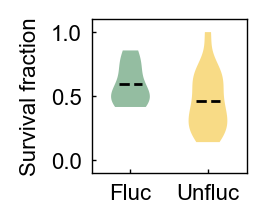

(<Figure size 200x200 with 1 Axes>, <Axes: ylabel='Survival fraction'>)

In [37]:
df_vali=pd.read_csv("C_surfrac_PLS1bin2_H_random2_v2.csv")
sub_f=df_vali[df_vali.iloc[:,-3]!=0]
sub_s=df_vali[df_vali.iloc[:,-3]==0]
plot_discrete_violin(sub_f.iloc[:,-1], sub_s.iloc[:,-1], figsize=(1, 1), 
                     save_path=f"C_surfrac_PLS1bin2_H_random2_v2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf")


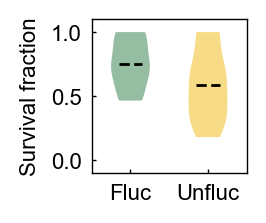

(<Figure size 200x200 with 1 Axes>, <Axes: ylabel='Survival fraction'>)

In [40]:
df_vali=pd.read_csv("C_surfrac_PLS1bin0_D_random2_v2.csv")
sub_f=df_vali[df_vali.iloc[:,-3]!=0]
sub_s=df_vali[df_vali.iloc[:,-3]==0]
plot_discrete_violin(sub_f.iloc[:,-1], sub_s.iloc[:,-1], figsize=(1, 1), 
                     save_path=f"C_surfrac_PLS1bin0_D_random2_v2_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf")
